In [2]:
# 1-D4

In [3]:
# 2-D4
# Check the image-classification dataset tools
# and prepare the MNIST dataset.

import torch
from torchvision import datasets, transforms


# Convert each MNIST image into a PyTorch tensor.
transform = transforms.ToTensor()


# Download/load the MNIST training dataset.
train_dataset = datasets.MNIST(
    root="../../datasets",
    train=True,
    download=True,
    transform=transform
)


# Download/load the MNIST test dataset.
test_dataset = datasets.MNIST(
    root="../../datasets",
    train=False,
    download=True,
    transform=transform
)


print("Training samples:", len(train_dataset))
print("Test samples:", len(test_dataset))


# Inspect one sample.
image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Label:", label)
print("Image data type:", image.dtype)

100.0%
100.0%
100.0%
100.0%


Training samples: 60000
Test samples: 10000
Image shape: torch.Size([1, 28, 28])
Label: 5
Image data type: torch.float32


In [6]:
# 3-D4
# Split the MNIST training dataset into
# training and validation subsets.

from torch.utils.data import random_split


# Define the number of samples for each subset.
train_size = 54000
validation_size = 6000


# Split the original training dataset.
train_subset, validation_subset = random_split(
    train_dataset,
    [train_size, validation_size],
    generator=torch.Generator().manual_seed(42)
)


print("Training subset:", len(train_subset))
print("Validation subset:", len(validation_subset))


# Inspect one sample from each subset.
train_image, train_label = train_subset[0]
validation_image, validation_label = validation_subset[0]


print("\nTraining sample:")
print("Image shape:", train_image.shape)
print("Label:", train_label)


print("\nValidation sample:")
print("Image shape:", validation_image.shape)
print("Label:", validation_label)

Training subset: 54000
Validation subset: 6000

Training sample:
Image shape: torch.Size([1, 28, 28])
Label: 6

Validation sample:
Image shape: torch.Size([1, 28, 28])
Label: 1


In [7]:
# 4-D4
# Create DataLoaders to provide training and validation
# data to the CNN in batches.

from torch.utils.data import DataLoader


# Define the number of images processed in one batch.
batch_size = 64


# Create the training DataLoader.
train_loader = DataLoader(
    train_subset,
    batch_size=batch_size,
    shuffle=True
)


# Create the validation DataLoader.
validation_loader = DataLoader(
    validation_subset,
    batch_size=batch_size,
    shuffle=False
)


# Get one batch from the training DataLoader.
train_images, train_labels = next(iter(train_loader))


# Get one batch from the validation DataLoader.
validation_images, validation_labels = next(iter(validation_loader))


print("Training batch image shape:", train_images.shape)
print("Training batch label shape:", train_labels.shape)

print("Validation batch image shape:", validation_images.shape)
print("Validation batch label shape:", validation_labels.shape)

Training batch image shape: torch.Size([64, 1, 28, 28])
Training batch label shape: torch.Size([64])
Validation batch image shape: torch.Size([64, 1, 28, 28])
Validation batch label shape: torch.Size([64])


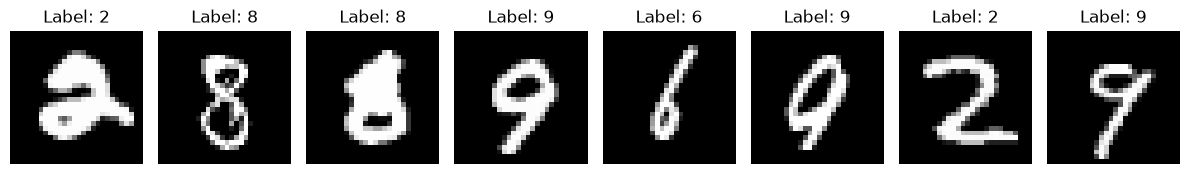

In [8]:
# 5-D4
# Visualize several images from one training batch
# together with their corresponding labels.

import matplotlib.pyplot as plt


# Select the first eight images from the batch.
images_to_show = train_images[:8]
labels_to_show = train_labels[:8]


# Create a row of eight image plots.
plt.figure(figsize=(12, 2))


for i in range(8):

    plt.subplot(1, 8, i + 1)

    # Remove the channel dimension for visualization.
    plt.imshow(
        images_to_show[i].squeeze(),
        cmap="gray"
    )

    plt.title(
        f"Label: {labels_to_show[i].item()}"
    )

    plt.axis("off")


plt.tight_layout()
plt.show()

In [9]:
# 6-D4
# Define the CNN classifier for MNIST digit classification.

import torch.nn as nn


class MNISTClassifier(nn.Module):

    def __init__(self):
        super().__init__()

        # First convolution:
        # 1 input channel (grayscale) -> 8 feature maps.
        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=8,
            kernel_size=3,
            padding=1
        )

        # Second convolution:
        # 8 feature maps -> 16 feature maps.
        self.conv2 = nn.Conv2d(
            in_channels=8,
            out_channels=16,
            kernel_size=3,
            padding=1
        )

        # Reduce the spatial dimensions by a factor of 2.
        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        # Fully connected classification layer.
        # After two pooling operations:
        # 16 feature maps × 7 × 7 = 784 values.
        self.fc = nn.Linear(
            16 * 7 * 7,
            10
        )

    def forward(self, x):

        # First convolution and activation.
        x = self.conv1(x)
        x = torch.relu(x)

        # First spatial reduction.
        x = self.pool(x)

        # Second convolution and activation.
        x = self.conv2(x)
        x = torch.relu(x)

        # Second spatial reduction.
        x = self.pool(x)

        # Flatten each image into a one-dimensional vector.
        x = x.view(
            x.size(0),
            -1
        )

        # Produce one output value for each digit class.
        x = self.fc(x)

        return x


model = MNISTClassifier()

print(model)

MNISTClassifier(
  (conv1): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc): Linear(in_features=784, out_features=10, bias=True)
)


In [10]:
# 7-D4
# Define the loss function and optimizer
# used to train the CNN.

# Cross-entropy loss measures the difference between
# the model's class scores and the correct class labels.
loss_function = nn.CrossEntropyLoss()


# Adam updates the CNN parameters using the gradients
# calculated during backpropagation.
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)


print("Loss function:", loss_function)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [11]:
# 8-D4
# Run one real training batch through the CNN
# and calculate the corresponding loss.

# Take one batch of real MNIST images.
images, labels = next(iter(train_loader))


# Pass the images through the CNN.
outputs = model(images)


# Compare the model outputs with the correct labels.
loss = loss_function(
    outputs,
    labels
)


print("Input batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Model output shape:", outputs.shape)
print("Loss:", loss.item())

Input batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])
Model output shape: torch.Size([64, 10])
Loss: 2.301894187927246


In [12]:
# 9-D4
# Inspect the CNN's initial prediction for one real image.

# Select the first image and its corresponding label.
single_image = images[0]
true_label = labels[0]


# Add the batch dimension back because the CNN expects a batch.
single_image_batch = single_image.unsqueeze(0)


# Run the image through the model.
single_output = model(single_image_batch)


# Find the class with the highest output score.
predicted_class = torch.argmax(
    single_output,
    dim=1
)


print("True label:", true_label.item())
print("Model output:", single_output)
print("Predicted class:", predicted_class.item())

True label: 8
Model output: tensor([[ 0.0038,  0.0578,  0.0462,  0.0256,  0.0103,  0.0088, -0.0650, -0.1077,
          0.1514, -0.0506]], grad_fn=<AddmmBackward0>)
Predicted class: 8


In [13]:
# 10-D4
# Perform one training step on a single batch.

# Start with cleared gradients.
optimizer.zero_grad()


# Forward pass:
# send the training images through the CNN.
outputs = model(images)


# Calculate how wrong the predictions are.
loss = loss_function(
    outputs,
    labels
)


# Backward pass:
# calculate gradients for the model parameters.
loss.backward()


# Update the model parameters using the gradients.
optimizer.step()


print("Training loss:", loss.item())

Training loss: 2.301894187927246


In [14]:
# 11-D4
# Measure the model output after the weight update.

# Run the same batch through the updated model.
updated_outputs = model(images)


# Calculate the new loss using the updated weights.
updated_loss = loss_function(
    updated_outputs,
    labels
)


print("Loss after weight update:", updated_loss.item())


# Get the predicted class for each image.
updated_predictions = torch.argmax(
    updated_outputs,
    dim=1
)


# Calculate the number of correct predictions.
correct_predictions = (
    updated_predictions == labels
).sum().item()


print("Correct predictions:", correct_predictions)
print("Batch size:", labels.size(0))

Loss after weight update: 2.284571647644043
Correct predictions: 9
Batch size: 64


In [15]:
# 12-D4
# Train the CNN for one epoch over the training dataset.

model.train()

running_loss = 0.0
correct = 0
total = 0


for batch_images, batch_labels in train_loader:

    # Clear gradients from the previous batch.
    optimizer.zero_grad()

    # Forward pass.
    outputs = model(batch_images)

    # Calculate the loss.
    loss = loss_function(
        outputs,
        batch_labels
    )

    # Backward pass.
    loss.backward()

    # Update model parameters.
    optimizer.step()

    # Accumulate the loss.
    running_loss += loss.item()

    # Determine the predicted class for each image.
    predictions = torch.argmax(
        outputs,
        dim=1
    )

    # Count correct predictions.
    correct += (
        predictions == batch_labels
    ).sum().item()

    total += batch_labels.size(0)


average_loss = running_loss / len(train_loader)
accuracy = 100 * correct / total


print("Training loss:", average_loss)
print("Training accuracy:", accuracy)

Training loss: 0.3607514693547411
Training accuracy: 89.47962962962963


In [16]:
# 13-D4
# Evaluate the trained CNN on the validation dataset.

model.eval()

validation_loss = 0.0
validation_correct = 0
validation_total = 0


with torch.no_grad():

    for batch_images, batch_labels in validation_loader:

        # Forward pass through the trained model.
        outputs = model(batch_images)

        # Calculate validation loss.
        loss = loss_function(
            outputs,
            batch_labels
        )

        validation_loss += loss.item()

        # Determine the predicted class.
        predictions = torch.argmax(
            outputs,
            dim=1
        )

        # Count correct predictions.
        validation_correct += (
            predictions == batch_labels
        ).sum().item()

        validation_total += batch_labels.size(0)


average_validation_loss = (
    validation_loss / len(validation_loader)
)

validation_accuracy = (
    100 * validation_correct / validation_total
)


print("Validation loss:", average_validation_loss)
print("Validation accuracy:", validation_accuracy)

Validation loss: 0.15406822304221543
Validation accuracy: 95.61666666666666


In [17]:
# 14-D4
# Evaluate the trained CNN on the separate MNIST test dataset.

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)


model.eval()

test_correct = 0
test_total = 0


with torch.no_grad():

    for batch_images, batch_labels in test_loader:

        outputs = model(batch_images)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        test_correct += (
            predictions == batch_labels
        ).sum().item()

        test_total += batch_labels.size(0)


test_accuracy = (
    100 * test_correct / test_total
)


print("Test correct predictions:", test_correct)
print("Test samples:", test_total)
print("Test accuracy:", test_accuracy)

Test correct predictions: 9630
Test samples: 10000
Test accuracy: 96.3
